target_vwap_up — средневзвешенная по объёму цена (VWAP) aFRR в направлении вверх (UP) на венгерском рынке, €/МВт·ч. Если в данный час активации не было, значение равно 0.

Признаки (это прогнозы на сутки вперёд, известные заранее):

- consumption — потребление электроэнергии, МВт·ч/ч
- wind — выработка ветровых станций, МВт·ч/ч
- solar — выработка солнечных станций, МВт·ч/ч
- nuclear — выработка АЭС, МВт·ч/ч
- temperature — температура, °C
- exchange_net_export — чистый экспорт (перетоки с соседними странами), МВт·ч/ч
- carbon_intensity_production — углеродоёмкость производства, кгCO₂-экв/МВт·ч

In [27]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../data/raw/hu_afrr_up_2023_2025.csv"

df = pd.read_csv(DATA_PATH)
df["datetime"] = pd.to_datetime(df["datetime"])
df = df.set_index("datetime").sort_index()

## Пропуски

In [29]:
missing = df.isna().sum()
print(missing)


consumption                        0
wind                               0
solar                              0
nuclear                            0
temperature                        0
exchange_net_export                0
carbon_intensity_production    26304
target_vwap_up                     0
dtype: int64


во всех столбцах пропусков нет, кроме carbon_intensity_production

## Описательная статистика

In [41]:
print("Описательная статистика:\n")
print(df.describe())
print("\nквантили:\n")
print(df.quantile([0.01, 0.05, 0.5, 0.95, 0.99]).T.round(2))
print("\nДоля часов без активации\n")
print((df["target_vwap_up"] == 0).mean())

Описательная статистика:

        consumption          wind         solar       nuclear   temperature  \
count  26304.000000  26304.000000  26304.000000  26304.000000  26304.000000   
mean    4892.350752     67.766200    614.154751   1731.613483     12.530437   
std      824.536399     62.834332    901.694901    236.125494      9.205871   
min     2342.180000      0.550000      0.000000    956.000000     -7.290000   
25%     4266.617500     17.650000      0.000000   1428.000000      4.850000   
50%     4827.590000     48.040000     30.090000   1900.000000     12.145000   
75%     5445.612500     99.250000   1045.035000   1900.000000     19.760000   
max     7336.580000    298.600000   4179.000000   1949.500000     35.910000   

       exchange_net_export  carbon_intensity_production  target_vwap_up  
count         26304.000000                          0.0    26304.000000  
mean          -1130.755820                          NaN       23.438314  
std            1227.783947              

1) target_vwap_up сильно скошен - при среднем значении 23.5 и медиане 3.9 максимум 213.
2) в 11% часов активации нет
   

## Сезонность

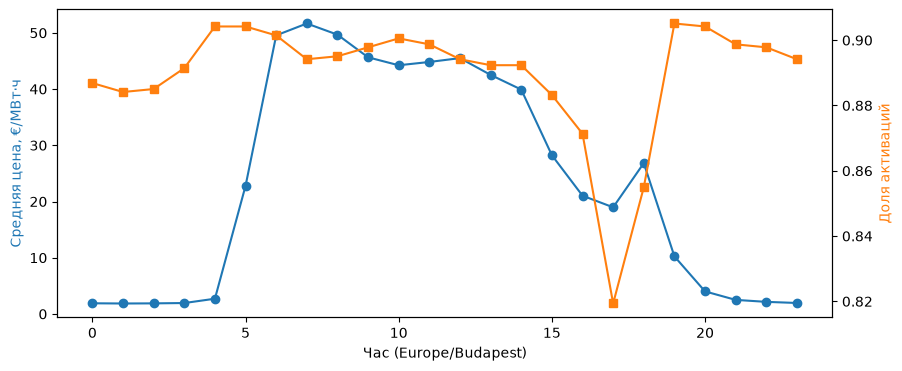

In [5]:
df["hour"] = df.index.hour
df["active"] = (df["target_vwap_up"] > 0).astype(int)
profile = df.groupby("hour").agg(cnt_actvation=("active", "mean"), mean_vwap_up=("target_vwap_up", "mean"))

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(profile.index, profile["mean_vwap_up"], marker="o", color="C0")
ax1.set_xlabel("Час (Europe/Budapest)")
ax1.set_ylabel("Средняя цена, €/МВт·ч", color="C0")

ax2 = ax1.twinx()
ax2.plot(profile.index, profile["cnt_actvation"], marker="s", color="C1")
ax2.set_ylabel("Доля активаций", color="C1")
plt.show()

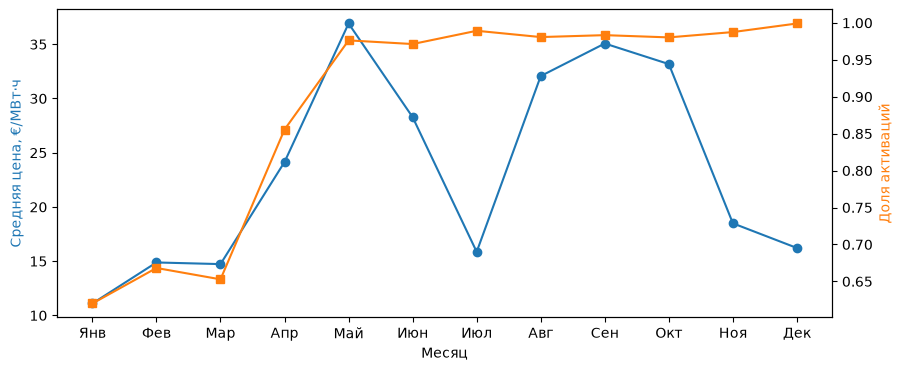

In [46]:

months = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн",
          "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]

df["month"] = df.index.month
profile = df.groupby("month").agg(
    cnt_actvation=("active", "mean"),
    mean_vwap_up=("target_vwap_up", "mean"),
)

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(profile.index, profile["mean_vwap_up"], marker="o", color="C0")
ax1.set_xlabel("Месяц")
ax1.set_ylabel("Средняя цена, €/МВт·ч", color="C0")
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(months)

ax2 = ax1.twinx()
ax2.plot(profile.index, profile["cnt_actvation"], marker="s", color="C1")
ax2.set_ylabel("Доля активаций", color="C1")
plt.show()

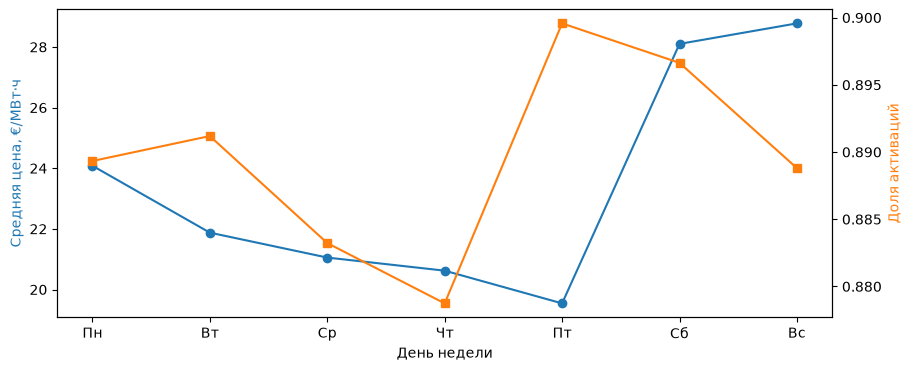

In [7]:
days = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]

df["weekday"] = df.index.weekday
profile = df.groupby("weekday").agg(
    cnt_actvation=("active", "mean"),
    mean_vwap_up=("target_vwap_up", "mean"),
)

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(profile.index, profile["mean_vwap_up"], marker="o", color="C0")
ax1.set_xlabel("День недели")
ax1.set_ylabel("Средняя цена, €/МВт·ч", color="C0")
ax1.set_xticks(range(7))
ax1.set_xticklabels(days)

ax2 = ax1.twinx()
ax2.plot(profile.index, profile["cnt_actvation"], marker="s", color="C1")
ax2.set_ylabel("Доля активаций", color="C1")
plt.show()

1) в сутках с 5:00 до 18:00 цена выше чем в ночное и вечернее время, а доля активаций почти не меняется
2) из месячного графика видно, что доля активаций возрастает с мая и держится на одном уровне до декабря, а в январе падает
3) на выходных средняя цена выше, доля активаций меньше всего в четверг.

## Распределение цен

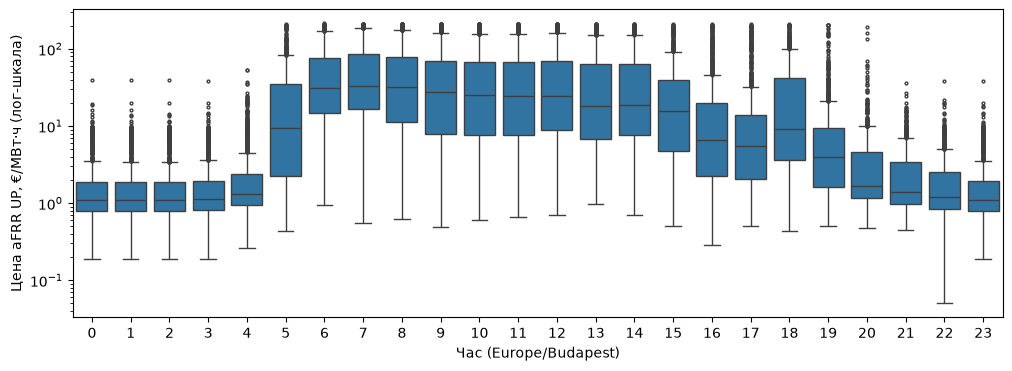

In [8]:
active = df[df["target_vwap_up"] > 0].copy()

plt.figure(figsize=(12, 4))
sns.boxplot(data=active, x="hour", y="target_vwap_up", fliersize=2)
plt.yscale("log")
plt.xlabel("Час (Europe/Budapest)")
plt.ylabel("Цена aFRR UP, €/МВт·ч (лог-шкала)")
plt.show()

1) ночью медианная цена меньше всего. днем и утром больше и с высоким разбросом 

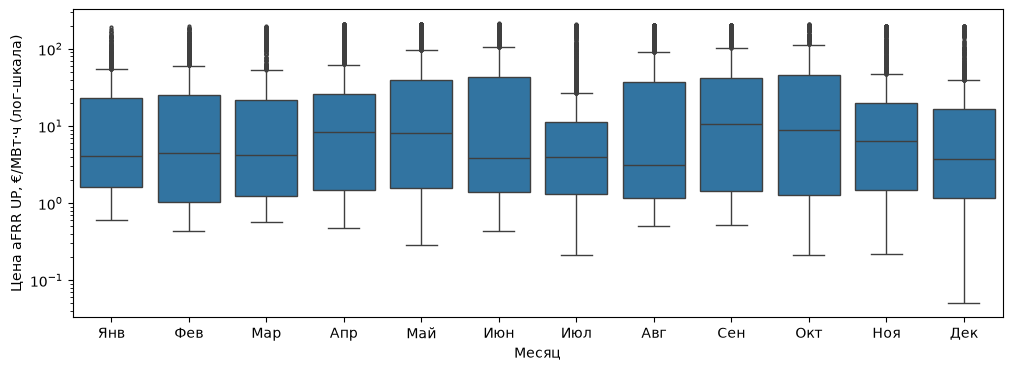

In [9]:
months = ["Янв", "Фев", "Мар", "Апр", "Май", "Июн",
          "Июл", "Авг", "Сен", "Окт", "Ноя", "Дек"]

plt.figure(figsize=(12, 4))
sns.boxplot(data=active, x="month", y="target_vwap_up", fliersize=2)
plt.yscale("log")
plt.xticks(range(12), months)
plt.xlabel("Месяц")
plt.ylabel("Цена aFRR UP, €/МВт·ч (лог-шкала)")
plt.show()

медианная цена держится на одном уровне

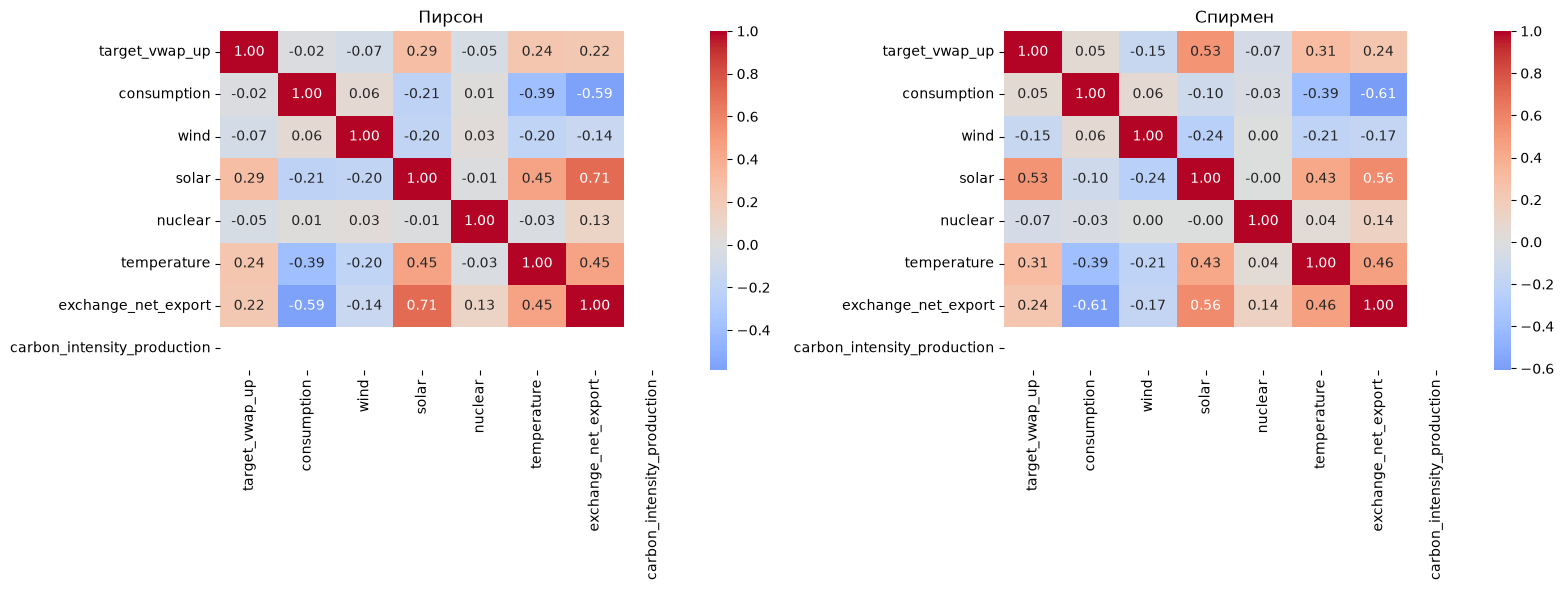

In [11]:
import seaborn as sns

cols = ["target_vwap_up", "consumption", "wind", "solar", "nuclear",
        "temperature", "exchange_net_export", "carbon_intensity_production"]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(df[cols].corr(method="pearson"), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Пирсон")
sns.heatmap(df[cols].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Спирмен")
plt.tight_layout()
plt.show()

Наболее высокая корелляция цены с solar по Пирсону и Спирмену. Почти нет корелляции с consumption, wind, nuclear. Также коррелируют exchange_net_export и solar

### Выбросы target_vwap_up

In [12]:
active = df.loc[df["target_vwap_up"] > 0, "target_vwap_up"]
q1, q3 = active.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

outliers_iqr = active[(active < low) | (active > high)]
print(f"Границы: {low:.1f} ... {high:.1f}")
print(f"Выбросов: {len(outliers_iqr)} из {len(active)} ({len(outliers_iqr)/len(active):.1%})")

Границы: -36.0 ... 63.6
Выбросов: 3103 из 23401 (13.3%)
